# Credit Risk Intelligence
### Previsão de inadimplência com aprendizado de máquina, avaliação de risco e decisões orientadas por dados

**Projeto end-to-end de Ciência de Dados | Python · pandas · scikit-learn · validação cruzada · modelagem supervisionada**

> **Pergunta de negócio:** dado o histórico financeiro dos últimos seis meses, conseguimos identificar clientes com maior probabilidade de não pagar no mês seguinte — e quanto isso melhora a priorização de uma equipe de análise de risco?

**Entregáveis:** análise exploratória, auditoria de dados, engenharia de atributos, benchmark de classificadores, experimentos controlados, teste separado, *ranking* top 10%, análise de erros, calibração, explicabilidade e artefatos reprodutíveis.

**Dados:** 30.000 clientes de cartões de crédito de Taiwan (2005), repositório UCI; 23 variáveis preditoras e alvo binário. [Dataset oficial](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) · [DOI](https://doi.org/10.24432/C55S3H).

**Escopo:** estudo retrospectivo de *ranking de risco*, **não** um sistema validado para concessão, negação ou precificação real de crédito. Resultados não podem ser generalizados para brasileiros ou para 2026.

## 01 · Visão executiva e protocolo

O foco não é maximizar acurácia. Em uma base com cerca de 22% de eventos, um classificador que sempre prevê “não inadimplente” pode parecer bom em acurácia e ser inútil para triagem. A métrica **principal para comparação** será **Average Precision (AP)**, que resume precisão ao longo de diferentes níveis de recall; ROC-AUC, F1, Brier score e métricas operacionais complementam a análise. A **AP de um classificador aleatório** tem como referência a prevalência do evento.

**Protocolo previamente definido**

1. Separação estratificada 80/20 com semente fixa. O teste fica intocado até o modelo, o conjunto de atributos e o limiar estarem escolhidos usando apenas treino/CV.
2. Auditoria e EDA centradas no treino. Pré-processamento, imputação e reamostragem sempre aprendidos dentro de cada *fold*.
3. Ablações: demografia × finanças; 1 mês × 6 meses; atributos originais × engenharia; balanceamento.
4. Seleção por AP média de validação cruzada; cálculo de predições **out-of-fold** para estudar o limiar antes de testar.
5. Teste realizado uma única vez; bootstrap para incerteza das métricas e revisão de calibração e subgrupos.

**Limites:** divisão aleatória entre clientes da mesma coorte histórica **não** equivale a validação fora do tempo; e risco estatístico não demonstra causalidade nem justiça de uma decisão.

## 02 · Ambiente e parâmetros de reprodução

Execução: Python 3.11+ em Jupyter/Colab. Instalar previamente com `pip install -r requirements.txt`; no Colab, a célula abaixo instala apenas dependências ausentes. Para executar com arquivo local, defina a variável de ambiente `CREDIT_DATA_LOCAL` com o caminho para `.csv`, `.xls` ou `.xlsx`. Sem ela, a origem padrão é a **UCI**.

In [1]:
import os, sys, json, hashlib, platform, importlib.util, subprocess, warnings
from pathlib import Path

# Instalação opcional somente para ambientes que não têm os pacotes essenciais.
for pacote_import, pacote_pip in [("ucimlrepo", "ucimlrepo>=0.0.7"), ("imblearn", "imbalanced-learn>=0.12")]:
    if importlib.util.find_spec(pacote_import) is None and (pacote_import != "ucimlrepo" or not os.getenv("CREDIT_DATA_LOCAL", "").strip()):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote_pip])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, imblearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay, make_scorer)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.inspection import permutation_importance
from joblib import dump

SEED = 42
RAPIDO = os.getenv("CREDIT_FAST_MODE", "0") == "1"  # Apenas para testes de desenvolvimento
CV = StratifiedKFold(n_splits=(2 if RAPIDO else 3), shuffle=True, random_state=SEED)
N_ARVORES = 35 if RAPIDO else 140
N_BOOST = 40 if RAPIDO else 130
PASTA_ARTEFATOS = Path("artefatos_credit_risk")
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 150, "axes.spines.right": False,
                     "axes.spines.top": False, "axes.titleweight": "semibold"})
pd.set_option("display.max_columns", 25)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


## 03 · Dados, procedência e qualidade

A variável `inadimplente` vale 1 se houve inadimplência no mês seguinte e 0 caso contrário. `PAY_0` se refere a **setembro de 2005**, `PAY_2` a agosto, e assim até abril (`PAY_6`). **Não existe `PAY_1`** nesse arquivo. Os códigos de atraso `-2` e `0`, e alguns códigos demográficos, não têm descrição inequívoca no dicionário oficial: eles serão preservados como categorias, sem imputar significados.

In [2]:
ATRASOS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
FATURAS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAGAMENTOS = [f"PAY_AMT{i}" for i in range(1, 7)]
DEMOGRAFIA = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FINANCEIROS = ["LIMIT_BAL", *ATRASOS, *FATURAS, *PAGAMENTOS]
COLUNAS = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", *ATRASOS, *FATURAS, *PAGAMENTOS]
assert len(COLUNAS) == 23

def carregar_dados(caminho_local=""):
    if caminho_local:
        caminho = Path(caminho_local)
        if not caminho.is_file():
            raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")
        if caminho.suffix.lower() == ".csv":
            df = pd.read_csv(caminho)
        elif caminho.suffix.lower() in (".xls", ".xlsx"):
            if caminho.suffix.lower() == ".xls" and importlib.util.find_spec("xlrd") is None:
                raise ImportError("Para ler o arquivo .xls original, instale 'xlrd>=2.0.1'.")
            previa = pd.read_excel(caminho, header=None, nrows=3)
            posicoes = [i for i in range(len(previa)) if "ID" in set(previa.iloc[i].astype(str))]
            if not posicoes:
                raise ValueError("Não foi localizado cabeçalho com ID nas 3 primeiras linhas.")
            df = pd.read_excel(caminho, header=posicoes[0])
        else:
            raise ValueError("Forneça CSV, XLS ou XLSX.")
        origem = f"Arquivo local: {caminho.name}"
    else:
        try:
            from ucimlrepo import fetch_ucirepo
            dataset = fetch_ucirepo(id=350)
            partes = []
            ids = getattr(dataset.data, "ids", None)
            if ids is not None:
                partes.append(ids.to_frame() if isinstance(ids, pd.Series) else ids)
            partes.extend([dataset.data.features, dataset.data.targets])
            df = pd.concat(partes, axis=1)
        except Exception as e:
            raise RuntimeError("A UCI não pôde ser acessada. Baixe o XLS oficial da UCI, "
                               "instale xlrd e defina CREDIT_DATA_LOCAL para executá-lo localmente.") from e
        origem = "UCI Machine Learning Repository (id=350)"
    mapa = {f"X{i}": col for i, col in enumerate(COLUNAS, start=1)}
    for alvo in ["Y", "default.payment.next.month", "default payment next month", "default_payment_next_month"]:
        mapa[alvo] = "inadimplente"
    df = df.rename(columns=lambda c: mapa.get(str(c).strip(), str(c).strip()))
    if df.columns.duplicated().any():
        raise ValueError("O arquivo tem colunas duplicadas após padronização.")
    faltando = sorted(set(COLUNAS + ["inadimplente"]) - set(df.columns))
    if faltando:
        raise ValueError(f"Colunas exigidas ausentes: {faltando}")
    if "ID" not in df.columns:
        df.insert(0, "ID", np.arange(1, len(df) + 1))
    return df[["ID", *COLUNAS, "inadimplente"]].copy(), origem

brutos, origem_dados = carregar_dados(os.getenv("CREDIT_DATA_LOCAL", "").strip())
dados = brutos.copy()
for coluna in dados.columns:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")
if dados["ID"].isna().any() or dados["ID"].duplicated().any():
    raise ValueError("Identificadores ausentes ou duplicados: é necessário investigar a origem.")
if dados["inadimplente"].isna().any() or not dados["inadimplente"].dropna().isin([0,1]).all():
    raise ValueError("O alvo deve ser binário e completo.")
dados["inadimplente"] = dados["inadimplente"].astype(int)
assert "inadimplente" not in COLUNAS and "ID" not in COLUNAS
print(f"Fonte: {origem_dados} | clientes: {len(dados):,} | atributos: {len(COLUNAS)}")
print(f"Taxa de evento observada: {dados['inadimplente'].mean():.2%}")
display(dados.head(3))

Fonte: UCI Machine Learning Repository (id=350) | clientes: 30,000 | atributos: 23
Taxa de evento observada: 22.12%


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,inadimplente
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [3]:
# Auditoria sem exclusão automática de extremos (valores financeiros podem ser legítimos).
auditoria = pd.DataFrame({
    "ausentes": dados.isna().sum(),
    "pct_ausentes": dados.isna().mean().mul(100).round(2),
    "n_unicos": dados.nunique(),
}).sort_values(["pct_ausentes", "n_unicos"], ascending=False)
alertas = pd.Series({
    "IDs duplicados": int(dados["ID"].duplicated().sum()),
    "Linhas duplicadas sem ID": int(dados.drop(columns="ID").duplicated().sum()),
    "EDUCATION códigos não documentados 0/5/6": int(dados.EDUCATION.isin([0,5,6]).sum()),
    "MARRIAGE código 0 não documentado": int(dados.MARRIAGE.eq(0).sum()),
    "Células PAY com códigos -2/0": int(dados[ATRASOS].isin([-2,0]).sum().sum()),
    "Faturas negativas (células)": int(dados[FATURAS].lt(0).sum().sum()),
    "Limites não positivos (clientes)": int(dados.LIMIT_BAL.le(0).sum()),
})
display(alertas.rename("Ocorrências").to_frame())
display(auditoria.query("ausentes > 0").head(10))
if dados[COLUNAS].isna().any().any():
    print("Ausências detectadas; imputação ocorrerá somente no treino, dentro de pipelines.")
else:
    print("Sem valores ausentes nos preditores (após conversão).")

,Ocorrências
IDs duplicados,0
Linhas duplicadas sem ID,35
EDUCATION códigos não documentados 0/5/6,345
MARRIAGE código 0 não documentado,54
Células PAY com códigos -2/0,120334
Faturas negativas (células),3932
Limites não positivos (clientes),0


,ausentes,pct_ausentes,n_unicos


Sem valores ausentes nos preditores (após conversão).


### Estratégia contra vazamento

O identificador e a variável-alvo são removidos antes do treinamento. A divisão por cliente precede qualquer exploração orientada pelo alvo. Como os seis meses pertencem ao histórico anterior ao evento, não constituem vazamento *por si só*; ainda assim, a janela exata de disponibilidade de cada variável exigiria revisão em uma implantação real.

In [4]:
X = dados[COLUNAS].copy()
y = dados["inadimplente"].copy()
X_treino_raw, X_teste_raw, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
assert X_treino_raw.index.is_unique and X_teste_raw.index.is_unique
assert set(X_treino_raw.index).isdisjoint(set(X_teste_raw.index))
resumo_particoes = pd.DataFrame([
    {"Partição": nome, "Clientes": len(yy), "Eventos": int(yy.sum()),
     "Taxa de inadimplência": f"{yy.mean():.2%}"}
    for nome, yy in [("Treino e CV",y_treino),("Teste reservado",y_teste)]
])
display(resumo_particoes)

,Partição,Clientes,Eventos,Taxa de inadimplência
0,Treino e CV,24000,5309,22.12%
1,Teste reservado,6000,1327,22.12%


## 04 · Exploração: onde está a informação de risco?

As figuras a seguir usam **somente clientes de treino**. A associação entre atraso registrado e inadimplência futura pode oferecer poder preditivo, mas não autoriza uma interpretação causal.

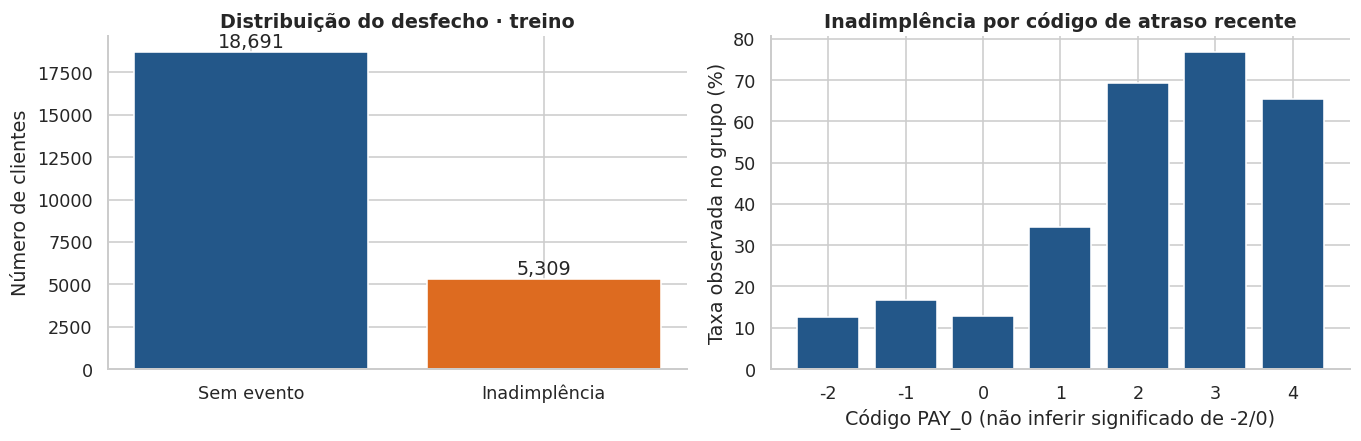

,PAY_0,taxa_evento,n_clientes
0,-2,0.127,2198
1,-1,0.166,4527
2,0,0.128,11781
3,1,0.344,3000
4,2,0.694,2138
5,3,0.767,245
6,4,0.655,58


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
contagens = y_treino.value_counts().reindex([0,1],fill_value=0)
ax[0].bar(["Sem evento", "Inadimplência"], contagens, color=["#235789", "#dd6b20"])
for i,v in enumerate(contagens): ax[0].text(i, v + max(contagens)*.015, f"{v:,}", ha="center")
ax[0].set(title="Distribuição do desfecho · treino", ylabel="Número de clientes")
tab_pay = (pd.DataFrame({"PAY_0": X_treino_raw["PAY_0"], "evento":y_treino})
           .groupby("PAY_0").evento.agg(["mean","size"]).reset_index())
tab_pay = tab_pay[tab_pay["size"] >= 20]
ax[1].bar(tab_pay["PAY_0"].astype(str), tab_pay["mean"].mul(100), color="#235789")
ax[1].set(title="Inadimplência por código de atraso recente",xlabel="Código PAY_0 (não inferir significado de -2/0)",ylabel="Taxa observada no grupo (%)")
plt.tight_layout(); plt.show()
display(tab_pay.rename(columns={"mean":"taxa_evento","size":"n_clientes"}).round(3))

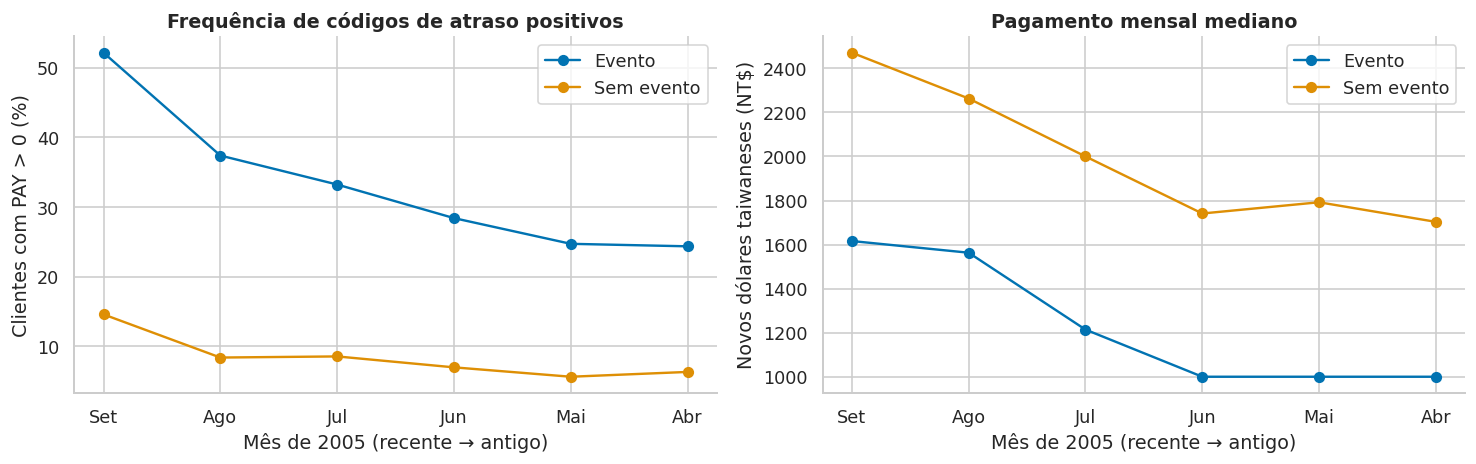

In [6]:
# Evolução histórica sem confundir histórico por cliente com validação fora do tempo.
meses = ["Set", "Ago", "Jul", "Jun", "Mai", "Abr"]
linhas_hist = []
for classe in (0,1):
    grupo = X_treino_raw.loc[y_treino.eq(classe)]
    for mes, coluna_atr, coluna_fat, coluna_pag in zip(meses, ATRASOS, FATURAS, PAGAMENTOS):
        linhas_hist.append({"Classe": "Evento" if classe else "Sem evento", "Mês": mes,
                            "Atraso > 0 (%)": grupo[coluna_atr].gt(0).mean()*100,
                            "Fatura mediana (NT$)": grupo[coluna_fat].median(),
                            "Pagamento mediano (NT$)": grupo[coluna_pag].median()})
historico = pd.DataFrame(linhas_hist)
fig, eixos = plt.subplots(1,2,figsize=(13,4.2))
for nome, g in historico.groupby("Classe"):
    eixos[0].plot(g["Mês"],g["Atraso > 0 (%)"],marker="o",label=nome)
    eixos[1].plot(g["Mês"],g["Pagamento mediano (NT$)"],marker="o",label=nome)
eixos[0].set(title="Frequência de códigos de atraso positivos",xlabel="Mês de 2005 (recente → antigo)",ylabel="Clientes com PAY > 0 (%)")
eixos[1].set(title="Pagamento mensal mediano",xlabel="Mês de 2005 (recente → antigo)",ylabel="Novos dólares taiwaneses (NT$)")
for a in eixos:a.legend()
plt.tight_layout(); plt.show()

## 05 · Engenharia de atributos baseada em comportamento

Usamos somente informações presentes nos seis meses anteriores ao desfecho. Os indicadores são determinísticos, isto é, não aprendem estatísticas da base e podem ser calculados separadamente para treino e teste. Limites nos quocientes evitam divisão por zero e explosão numérica; não são tratamentos para “corrigir” observações reais.

In [7]:
FEATURES_NOVAS = ["meses_atraso_positivo", "maior_atraso_positivo", "meses_sem_pagamento",
                 "fatura_media", "fatura_volatilidade", "pagamento_medio",
                 "utilizacao_recente", "relacao_pagamentos_faturas", "tendencia_fatura_limite"]

def engenharia_atributos(df):
    novo = df.copy()
    atraso = novo[ATRASOS]
    faturas = novo[FATURAS]
    pagamentos = novo[PAGAMENTOS]
    limite_seguro = novo["LIMIT_BAL"].clip(lower=1.0)
    novo["meses_atraso_positivo"] = atraso.gt(0).sum(axis=1)
    novo["maior_atraso_positivo"] = atraso.clip(lower=0).max(axis=1)
    novo["meses_sem_pagamento"] = pagamentos.eq(0).sum(axis=1)
    novo["fatura_media"] = faturas.mean(axis=1)
    novo["fatura_volatilidade"] = faturas.std(axis=1).fillna(0)
    novo["pagamento_medio"] = pagamentos.mean(axis=1)
    novo["utilizacao_recente"] = (novo["BILL_AMT1"].clip(lower=0) / limite_seguro).clip(0, 10)
    soma_faturas_positivas = faturas.clip(lower=0).sum(axis=1)
    # Razão agregada descritiva; pagamentos e faturas não necessariamente liquidam o mesmo período.
    novo["relacao_pagamentos_faturas"] = (
        pagamentos.clip(lower=0).sum(axis=1) / soma_faturas_positivas.clip(lower=1)
    ).clip(0, 10)
    novo["tendencia_fatura_limite"] = ((novo["BILL_AMT1"]-novo["BILL_AMT6"])
                                        / limite_seguro).clip(-10,10)
    return novo

X_treino = engenharia_atributos(X_treino_raw)
X_teste = engenharia_atributos(X_teste_raw)
assert list(X_treino.columns) == list(X_teste.columns)
assert len(X_treino) == len(y_treino) and len(X_teste) == len(y_teste)
assert not X_treino[FEATURES_NOVAS].isna().any().any()

CONJUNTOS = {
    "Somente demográficos": DEMOGRAFIA,
    "Financeiros · último mês": ["LIMIT_BAL", "PAY_0", "BILL_AMT1", "PAY_AMT1"],
    "Financeiros · 6 meses": FINANCEIROS,
    "Financeiros + engenharia": [*FINANCEIROS, *FEATURES_NOVAS],
    "Todos os originais": COLUNAS,
}
for nome, cols in CONJUNTOS.items():
    assert set(cols).issubset(X_treino.columns), nome
print("Atributos novos:", ", ".join(FEATURES_NOVAS))
print("Conjuntos experimentais:", {nome:len(cols) for nome,cols in CONJUNTOS.items()})

Atributos novos: meses_atraso_positivo, maior_atraso_positivo, meses_sem_pagamento, fatura_media, fatura_volatilidade, pagamento_medio, utilizacao_recente, relacao_pagamentos_faturas, tendencia_fatura_limite
Conjuntos experimentais: {'Somente demográficos': 4, 'Financeiros · último mês': 4, 'Financeiros · 6 meses': 19, 'Financeiros + engenharia': 28, 'Todos os originais': 23}


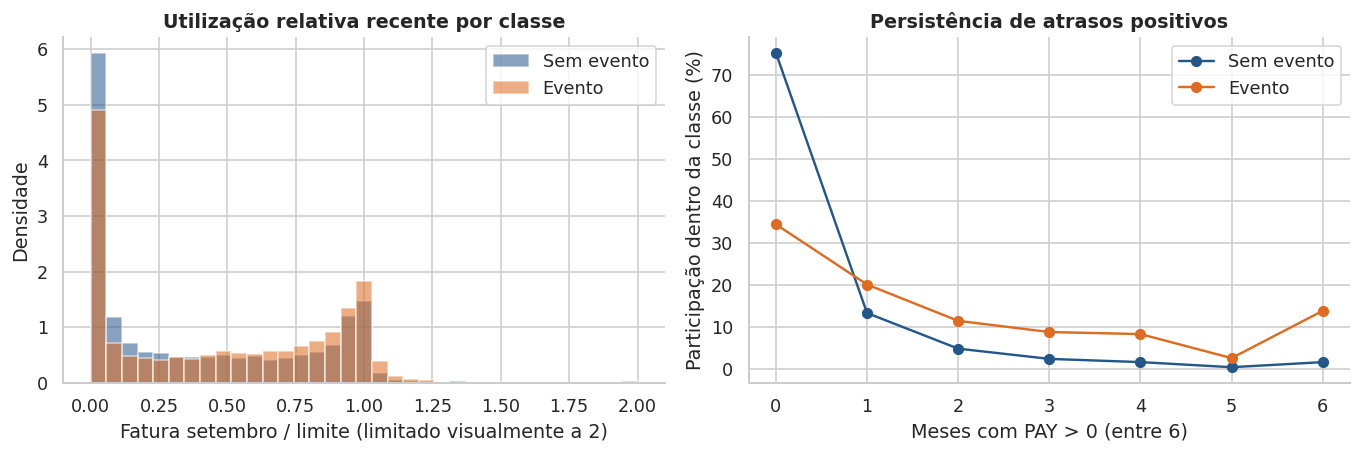

In [8]:
fig,axs=plt.subplots(1,2,figsize=(12,4.1))
for classe, rotulo, cor in [(0,"Sem evento","#235789"),(1,"Evento","#dd6b20")]:
    fat = X_treino.loc[y_treino.eq(classe),"utilizacao_recente"].clip(upper=2)
    axs[0].hist(fat,bins=35,alpha=.55,density=True,label=rotulo,color=cor)
    conta = X_treino.loc[y_treino.eq(classe),"meses_atraso_positivo"].value_counts(normalize=True)
    axs[1].plot(range(7), [conta.get(j,0)*100 for j in range(7)], marker="o",label=rotulo,color=cor)
axs[0].set(title="Utilização relativa recente por classe",xlabel="Fatura setembro / limite (limitado visualmente a 2)",ylabel="Densidade")
axs[1].set(title="Persistência de atrasos positivos",xlabel="Meses com PAY > 0 (entre 6)",ylabel="Participação dentro da classe (%)")
for ax in axs:ax.legend()
plt.tight_layout();plt.show()

## 06 · Experimentos controlados e validação cruzada

Uma avaliação de projeto é mais convincente quando isola escolhas. Primeiro comparamos **representações de informação** mantendo o classificador constante; depois comparamos **algoritmos**, aplicando exatamente os mesmos folds e critérios. Variáveis demográficas entram somente como **referência científica para a ablação**; a seleção operacional restringe-se a variáveis financeiras.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Modelo,Nº atributos,ap,ap_dp,roc_auc,f1,brier
0,Financeiros + engenharia,28,0.5434,0.0105,0.7736,0.4721,0.1356
1,Todos os originais,23,0.5425,0.0164,0.7687,0.4704,0.1361
2,Financeiros · 6 meses,19,0.5398,0.0135,0.7664,0.4686,0.1366
3,Financeiros · último mês,4,0.5142,0.0024,0.7489,0.4392,0.1393
4,Somente demográficos,4,0.2557,0.0064,0.5590,0.0000,0.1710


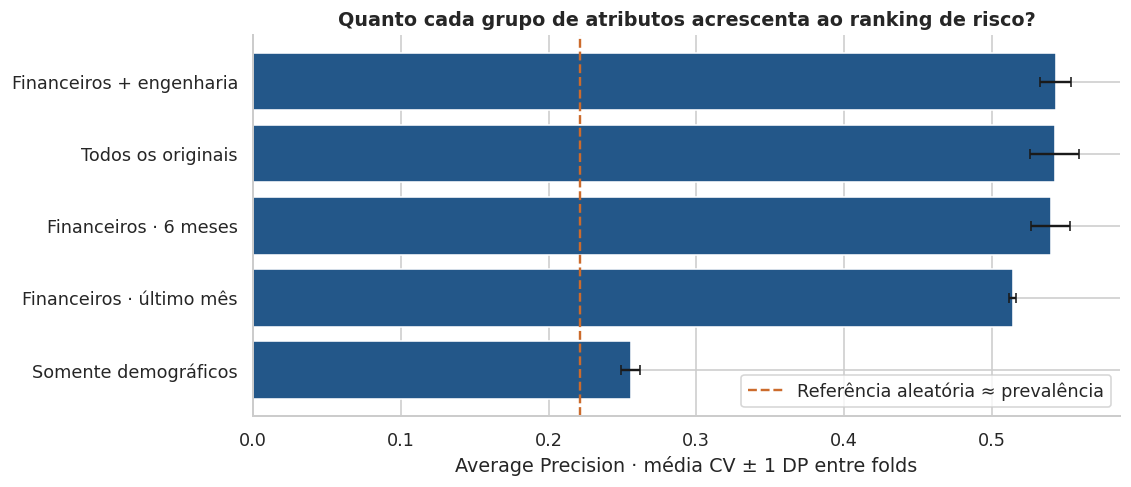

In [9]:
CATEGORICAS = ["SEX","EDUCATION","MARRIAGE",*ATRASOS]

def preprocessar(cols):
    num = [c for c in cols if c not in CATEGORICAS]
    cat = [c for c in cols if c in CATEGORICAS]
    parts = []
    if num:
        parts.append(("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler())]), num))
    if cat:
        parts.append(("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    return ColumnTransformer(parts, remainder="drop", sparse_threshold=0)

def montar(modelo, cols, sampler=None):
    passos = [("preparar", preprocessar(cols))]
    if sampler is not None:
        passos.append(("amostrar", sampler))
    passos.append(("modelo", modelo))
    return ImbPipeline(passos)

SCORING = {
    "ap": "average_precision", "roc_auc": "roc_auc",
    "f1": "f1", "recall": "recall", "precision": "precision",
    "accuracy": "accuracy", "brier": "neg_brier_score"
}

def validar(nome, pipeline, cols):
    scores = cross_validate(pipeline, X_treino[cols], y_treino, scoring=SCORING,
                            cv=CV, n_jobs=1, error_score="raise")
    linha = {"Modelo": nome, "Nº atributos":len(cols)}
    for metr in SCORING:
        valores=scores["test_"+metr]*(-1 if metr=="brier" else 1)
        linha[metr] = float(np.mean(valores))
        linha[metr+"_dp"] = float(np.std(valores,ddof=1))
    linha["tempo_cv_s"] = float(np.sum(scores["fit_time"]+scores["score_time"]))
    return linha

modelo_ab = LogisticRegression(C=0.5, max_iter=1500, random_state=SEED)
resultados_ablacao = pd.DataFrame([
    validar(nome,montar(clone(modelo_ab),cols),cols)
    for nome,cols in CONJUNTOS.items()
]).sort_values("ap",ascending=False).reset_index(drop=True)
display(resultados_ablacao[["Modelo","Nº atributos","ap","ap_dp","roc_auc","f1","brier"]].round(4))
fig,ax=plt.subplots(figsize=(10,4.4))
plot_data=resultados_ablacao.sort_values("ap")
ax.barh(plot_data["Modelo"],plot_data["ap"],xerr=plot_data["ap_dp"],capsize=3,color="#235789")
ax.axvline(y_treino.mean(),ls="--",c="#cc6b2c",label="Referência aleatória ≈ prevalência")
ax.set(xlabel="Average Precision · média CV ± 1 DP entre folds",title="Quanto cada grupo de atributos acrescenta ao ranking de risco?")
ax.legend(loc="lower right");plt.tight_layout();plt.show()

In [10]:
# Regra pré-definida: escolher a representação financeira com maior AP média na CV.
financeiros_candidatos = resultados_ablacao[
    resultados_ablacao["Modelo"].isin(["Financeiros · 6 meses", "Financeiros + engenharia"])]
conjunto_escolhido = financeiros_candidatos.sort_values(
    ["ap", "roc_auc"],ascending=False).iloc[0]["Modelo"]
cols_modelo = CONJUNTOS[conjunto_escolhido]
print(f"Representação selecionada por CV no treino: {conjunto_escolhido} ({len(cols_modelo)} atributos)")
print("A comparação foi realizada no treino. O teste ainda não foi consultado.")

Representação selecionada por CV no treino: Financeiros + engenharia (28 atributos)
A comparação foi realizada no treino. O teste ainda não foi consultado.


### Comparação de modelos

Todos os candidatos usam a mesma representação financeira. A regressão logística é referência interpretável; árvore e Random Forest capturam interações; *gradient boosting* oferece alternativa não linear; Naive Bayes testa independência condicional; SVM linear calibrado testa uma margem regularizada. Os hiperparâmetros são **configurações fixas**, não resultados de tuning contra o teste. O ranking por CV é exploratório e pode carregar viés de seleção; o teste separado limita essa preocupação.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Modelo,ap,ap_dp,roc_auc,f1,recall,precision,brier,tempo_cv_s
0,Gradient Boosting,0.5585,0.0080,0.7843,0.4786,0.3711,0.6742,0.1340,3.8294
1,Random Forest,0.5546,0.0093,0.7859,0.4762,0.3667,0.6790,0.1341,20.6269
2,SVM linear calibrado,0.5453,0.0109,0.7727,0.4673,0.3545,0.6855,0.1359,2.7581
3,Regressão logística,0.5434,0.0105,0.7736,0.4721,0.3635,0.6732,0.1356,6.8113
4,Árvore de decisão,0.5254,0.0101,0.7720,0.4547,0.3454,0.6718,0.1371,4.6028
5,Naive Bayes,0.5098,0.0214,0.7506,0.5251,0.5615,0.4951,0.1944,0.7980
6,Dummy · prevalência,0.2212,0.0001,0.5000,0.0000,0.0000,0.0000,0.1723,1.0553


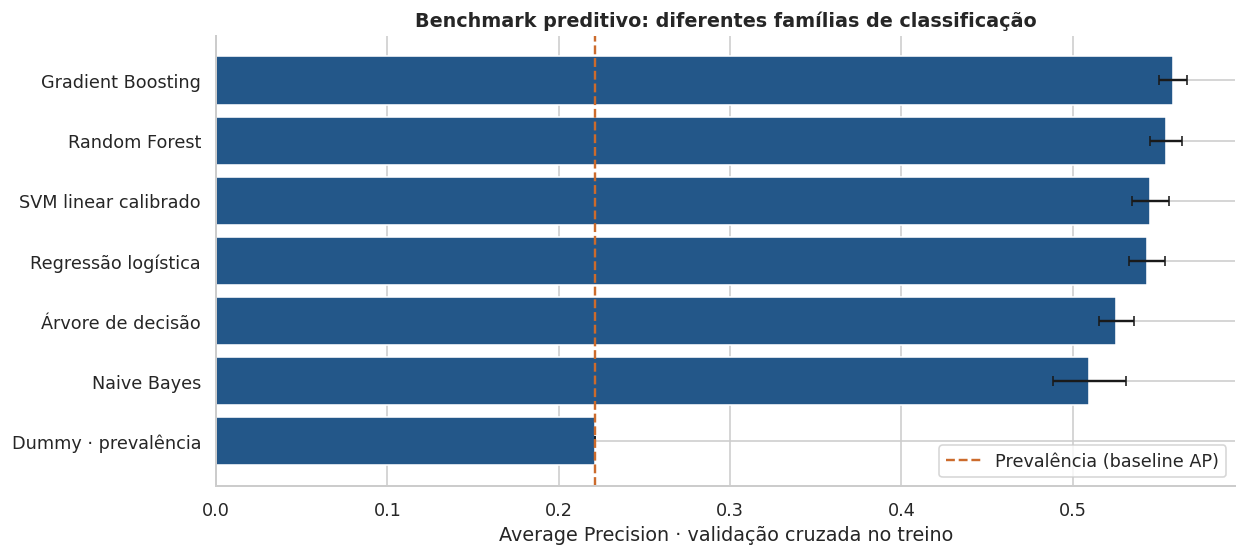

In [11]:
MODELOS = {
    "Dummy · prevalência": DummyClassifier(strategy="prior"),
    "Regressão logística": LogisticRegression(C=0.5,max_iter=1500,random_state=SEED),
    "Árvore de decisão": DecisionTreeClassifier(max_depth=6,min_samples_leaf=80,random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=N_ARVORES,max_depth=14,
                                              min_samples_leaf=25,n_jobs=2,random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=N_BOOST,learning_rate=.08,
                                  max_leaf_nodes=18,l2_regularization=2,random_state=SEED),
    "Naive Bayes": GaussianNB(var_smoothing=0.1),
    "SVM linear calibrado": CalibratedClassifierCV(LinearSVC(C=0.05,dual=False,
                                  random_state=SEED,max_iter=3000),method="sigmoid",cv=3),
}
modelos_pipeline={nome:montar(clone(modelo),cols_modelo) for nome,modelo in MODELOS.items()}
resultados_modelos=pd.DataFrame([
    validar(nome,pipe,cols_modelo) for nome,pipe in modelos_pipeline.items()
]).sort_values("ap",ascending=False).reset_index(drop=True)
display(resultados_modelos[["Modelo","ap","ap_dp","roc_auc","f1","recall","precision","brier","tempo_cv_s"]].round(4))
fig,ax=plt.subplots(figsize=(11,5))
ordem=resultados_modelos.sort_values("ap")
ax.barh(ordem["Modelo"],ordem["ap"],xerr=ordem["ap_dp"],capsize=3,color="#235789")
ax.axvline(y_treino.mean(),ls="--",c="#cc6b2c",label="Prevalência (baseline AP)")
ax.set(xlabel="Average Precision · validação cruzada no treino",title="Benchmark preditivo: diferentes famílias de classificação")
ax.legend();plt.tight_layout();plt.show()

### Balanceamento: e a troca entre precisão e sensibilidade?

A taxa de eventos não será artificialmente modificada no conjunto de validação ou teste. Pesos de classe, *oversampling* e *undersampling* são aplicados **apenas ao pedaço de ajuste de cada fold** via `imblearn.Pipeline`. Fixamos o classificador logístico para separar o efeito do balanceamento da escolha do algoritmo. O objetivo é avaliar o compromisso entre métricas, não pressupor que recall máximo é melhor.

,Modelo,ap,roc_auc,recall,precision,f1,brier
0,Logística sem reamostragem,0.5434,0.7736,0.3635,0.6732,0.4721,0.1356
1,Logística com pesos,0.5414,0.7739,0.6255,0.4570,0.5281,0.1838
2,Logística com oversampling,0.5403,0.7736,0.6282,0.4577,0.5295,0.1840
3,Logística com undersampling,0.5375,0.7733,0.6269,0.4528,0.5257,0.1853


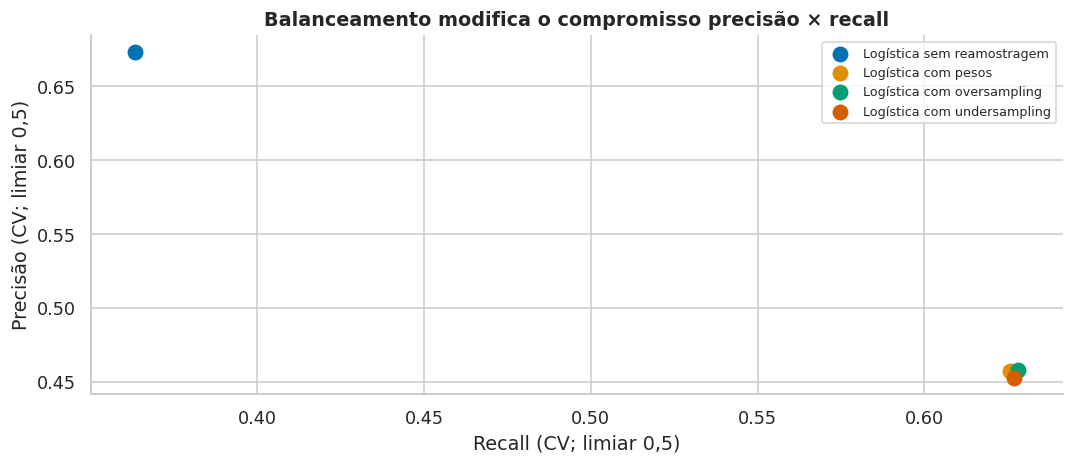

In [12]:
BALANCEAMENTOS = {
    "Logística sem reamostragem": montar(LogisticRegression(C=.5,max_iter=1500,random_state=SEED),cols_modelo),
    "Logística com pesos": montar(LogisticRegression(C=.5,max_iter=1500,class_weight="balanced",random_state=SEED),cols_modelo),
    "Logística com oversampling": montar(LogisticRegression(C=.5,max_iter=1500,random_state=SEED),cols_modelo,
                                         RandomOverSampler(random_state=SEED)),
    "Logística com undersampling": montar(LogisticRegression(C=.5,max_iter=1500,random_state=SEED),cols_modelo,
                                          RandomUnderSampler(random_state=SEED)),
}
resultado_balanceamento = pd.DataFrame([
    validar(nome,pipe,cols_modelo) for nome,pipe in BALANCEAMENTOS.items()
]).sort_values("ap",ascending=False).reset_index(drop=True)
display(resultado_balanceamento[["Modelo","ap","roc_auc","recall","precision","f1","brier"]].round(4))
fig,ax=plt.subplots(figsize=(9.5,4.2))
for _,r in resultado_balanceamento.iterrows():
    ax.scatter(r["recall"],r["precision"],s=80,label=r["Modelo"])
ax.set(title="Balanceamento modifica o compromisso precisão × recall",xlabel="Recall (CV; limiar 0,5)",ylabel="Precisão (CV; limiar 0,5)")
ax.legend(fontsize=8,loc="best");plt.tight_layout();plt.show()

In [13]:
# Escolha única por AP de CV, incluindo alternativas com reamostragem.
# Regra de desempate: ROC-AUC, depois nome em ordem alfabética (determinismo).
candidatos={**modelos_pipeline,
    **{k:v for k,v in BALANCEAMENTOS.items() if k!="Logística sem reamostragem"}}
ranking=pd.concat([resultados_modelos, resultado_balanceamento[
    resultado_balanceamento["Modelo"]!="Logística sem reamostragem"]],ignore_index=True)
ranking=ranking.sort_values(["ap","roc_auc","Modelo"],ascending=[False,False,True]).reset_index(drop=True)
nome_vencedor=ranking.loc[0,"Modelo"]
pipeline_vencedor=candidatos[nome_vencedor]
assert nome_vencedor!="Dummy · prevalência", "Baseline venceu: repensar modelagem antes da publicação."
print(f"Modelo selecionado: {nome_vencedor}")
print(f"AP CV média: {ranking.loc[0,'ap']:.4f} | DP entre folds: {ranking.loc[0,'ap_dp']:.4f}")
display(ranking[["Modelo","ap","ap_dp","roc_auc","brier"]].round(4))

Modelo selecionado: Gradient Boosting
AP CV média: 0.5585 | DP entre folds: 0.0080


,Modelo,ap,ap_dp,roc_auc,brier
0,Gradient Boosting,0.5585,0.0080,0.7843,0.1340
1,Random Forest,0.5546,0.0093,0.7859,0.1341
2,SVM linear calibrado,0.5453,0.0109,0.7727,0.1359
3,Regressão logística,0.5434,0.0105,0.7736,0.1356
4,Logística com pesos,0.5414,0.0120,0.7739,0.1838
5,Logística com oversampling,0.5403,0.0106,0.7736,0.1840
6,Logística com undersampling,0.5375,0.0111,0.7733,0.1853
7,Árvore de decisão,0.5254,0.0101,0.7720,0.1371
8,Naive Bayes,0.5098,0.0214,0.7506,0.1944
9,Dummy · prevalência,0.2212,0.0001,0.5000,0.1723


### O que os experimentos indicam? · H1–H5

As hipóteses são discutidas com **diferenças observadas na média de CV** — não como prova de causalidade ou de significância estatística. As métricas de classificação das variantes balanceadas dependem do limiar fixo de 0,50; compará-las com a AP evita escolher apenas pela quantidade de positivos previstos.

In [14]:
def valor_ap_ab(nome):
    return float(resultados_ablacao.set_index("Modelo").loc[nome,"ap"])

def valor_metrica_bal(nome,metrica):
    return float(resultado_balanceamento.set_index("Modelo").loc[nome,metrica])

comparacoes = pd.DataFrame([
    {"Hipótese":"H1 · Informações financeiras vs demografia",
     "Referência AP":valor_ap_ab("Somente demográficos"),
     "Comparação AP":valor_ap_ab("Financeiros · 6 meses")},
    {"Hipótese":"H2 · 6 meses vs último mês",
     "Referência AP":valor_ap_ab("Financeiros · último mês"),
     "Comparação AP":valor_ap_ab("Financeiros · 6 meses")},
    {"Hipótese":"H3 · Engenharia vs variáveis financeiras originais",
     "Referência AP":valor_ap_ab("Financeiros · 6 meses"),
     "Comparação AP":valor_ap_ab("Financeiros + engenharia")},
    {"Hipótese":"H4 · Melhor balanceamento logístico vs original",
     "Referência AP":valor_metrica_bal("Logística sem reamostragem","ap"),
     "Comparação AP":float(resultado_balanceamento.ap.max())},
    {"Hipótese":"H5 · Melhor classificador vs logística padrão",
     "Referência AP":float(resultados_modelos.set_index("Modelo").loc["Regressão logística","ap"]),
     "Comparação AP":float(ranking.iloc[0].ap)},
])
comparacoes["Diferença AP (p.p.)"] = (comparacoes["Comparação AP"] - comparacoes["Referência AP"])*100
comparacoes["Leitura descritiva"] = np.select(
    [comparacoes["Diferença AP (p.p.)"] > 0.5, comparacoes["Diferença AP (p.p.)"] < -0.5],
    ["Indício favorável na CV", "Indício desfavorável na CV"],default="Diferença pequena na CV")
display(comparacoes.round(3))
print("Diferenças calculadas na validação cruzada, NÃO inferências causais ou testes formais de significância.")


,Hipótese,Referência AP,Comparação AP,Diferença AP (p.p.),Leitura descritiva
0,H1 · Informações financeiras vs demografia,0.256,0.540,28.407,Indício favorável na CV
1,H2 · 6 meses vs último mês,0.514,0.540,2.554,Indício favorável na CV
2,H3 · Engenharia vs variáveis financeiras origi...,0.540,0.543,0.364,Diferença pequena na CV
3,H4 · Melhor balanceamento logístico vs original,0.543,0.543,0.000,Diferença pequena na CV
4,H5 · Melhor classificador vs logística padrão,0.543,0.559,1.515,Indício favorável na CV


Diferenças calculadas na validação cruzada, NÃO inferências causais ou testes formais de significância.


## 07 · Política de classificação sem consultar o teste

O valor 0,50 não é intrinsecamente ótimo. A partir de probabilidades **fora do fold** geradas somente no treino, calculamos o limiar que maximiza F1 (critério estatístico ilustrativo, **sem** custo de falso positivo/negativo fornecido pelo banco). Para uma operação com capacidade restrita, avaliaremos separadamente o **top 10% por score**: esta decisão usa *ranking*, não um limiar fixo.

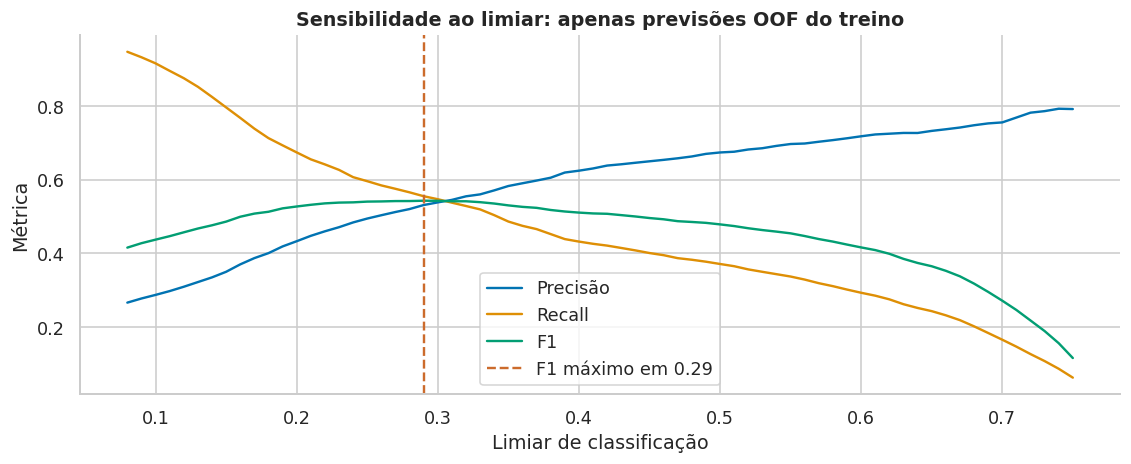

Limiar congelado antes do teste: 0.29


In [15]:
# Nenhuma previsão desta célula usa o teste.
prob_oof = cross_val_predict(clone(pipeline_vencedor),X_treino[cols_modelo],y_treino,
                             cv=CV,method="predict_proba",n_jobs=1)[:,1]
limiares = np.linspace(0.08,0.75,68)
def métricas_limiar(y_true,probs,limiar):
    yp=(np.asarray(probs)>=limiar).astype(int)
    return {"limiar":float(limiar),"precisao":precision_score(y_true,yp,zero_division=0),
            "recall":recall_score(y_true,yp,zero_division=0),
            "f1":f1_score(y_true,yp,zero_division=0)}
tabela_limiares=pd.DataFrame([métricas_limiar(y_treino,prob_oof,x) for x in limiares])
limiar_escolhido=float(tabela_limiares.sort_values(["f1","limiar"],ascending=[False,True]).iloc[0]["limiar"])
fig,ax=plt.subplots(figsize=(10,4.2))
for col,lab in [("precisao","Precisão"),("recall","Recall"),("f1","F1")]:
    ax.plot(tabela_limiares["limiar"],tabela_limiares[col],label=lab)
ax.axvline(limiar_escolhido,c="#cc6b2c",ls="--",label=f"F1 máximo em {limiar_escolhido:.2f}")
ax.set(title="Sensibilidade ao limiar: apenas previsões OOF do treino",xlabel="Limiar de classificação",ylabel="Métrica")
ax.legend();plt.tight_layout();plt.show()
print("Limiar congelado antes do teste:",round(limiar_escolhido,3))

In [16]:
def metricas_top_frac(y_true,score,frac=0.10):
    y_a=np.asarray(y_true,dtype=int)
    p_a=np.asarray(score,dtype=float)
    k=max(1,int(np.ceil(frac*len(y_a))))
    ranking_idx=np.argsort(-p_a,kind="stable")[:k]
    encontrados=int(y_a[ranking_idx].sum())
    base=float(y_a.mean())
    return {"selecionados":k,"eventos_selecionados":encontrados,
            "precision_at_10":encontrados/k,"recall_at_10":encontrados/max(int(y_a.sum()),1),
            "lift_at_10":(encontrados/k)/base if base>0 else np.nan,
            "taxa_base":base}

triagem_oof = metricas_top_frac(y_treino,prob_oof)
print("Viabilidade interna (OOF), ainda não teste:")
display(pd.Series(triagem_oof).to_frame("Valor").round(4))

Viabilidade interna (OOF), ainda não teste:


,Valor
selecionados,2400.0000
eventos_selecionados,1689.0000
precision_at_10,0.7038
recall_at_10,0.3181
lift_at_10,3.1814
taxa_base,0.2212


## 08 · Teste reservado: generalização e utilidade operacional

**A partir daqui o protocolo fica congelado**: representação, algoritmo e limiar já foram selecionados. A avaliação a seguir é a única utilização do conjunto de teste para estimar generalização. O bootstrap estratificado abaixo quantifica variação amostral **condicional a este conjunto de teste**, não incerteza de mudanças futuras de população ou do treinamento.

,Resultado no teste
modelo,Gradient Boosting
representacao,Financeiros + engenharia
limiar,0.29
n_teste,6000
n_eventos,1327
prevalencia_teste,0.221167
average_precision,0.553269
roc_auc,0.780296
accuracy,0.792167
precision,0.528169


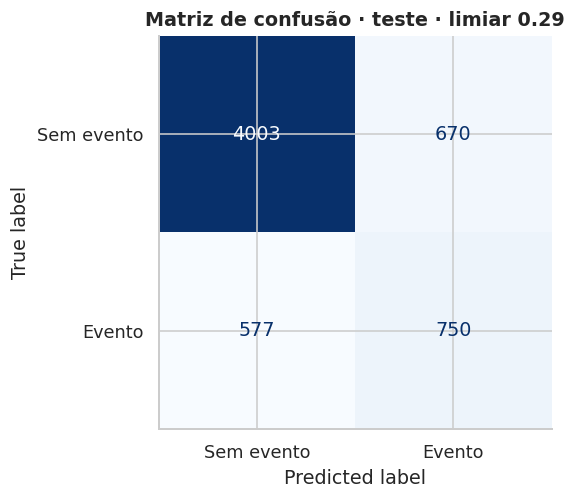

In [17]:
modelo_final=clone(pipeline_vencedor).fit(X_treino[cols_modelo],y_treino)
prob_teste=modelo_final.predict_proba(X_teste[cols_modelo])[:,1]
pred_teste=(prob_teste>=limiar_escolhido).astype(int)
metricas_teste={
    "modelo":nome_vencedor,"representacao":conjunto_escolhido,"limiar":limiar_escolhido,
    "n_teste":int(len(y_teste)),"n_eventos":int(y_teste.sum()),
    "prevalencia_teste":float(y_teste.mean()),
    "average_precision":float(average_precision_score(y_teste,prob_teste)),
    "roc_auc":float(roc_auc_score(y_teste,prob_teste)),
    "accuracy":float(accuracy_score(y_teste,pred_teste)),
    "precision":float(precision_score(y_teste,pred_teste,zero_division=0)),
    "recall":float(recall_score(y_teste,pred_teste,zero_division=0)),
    "f1":float(f1_score(y_teste,pred_teste,zero_division=0)),
    "brier":float(brier_score_loss(y_teste,prob_teste)),
}
metricas_teste.update(metricas_top_frac(y_teste,prob_teste))
display(pd.Series(metricas_teste).to_frame("Resultado no teste"))
cm=confusion_matrix(y_teste,pred_teste)
assert cm.sum()==len(y_teste)
fig, ax=plt.subplots(figsize=(5.6,4.5))
ConfusionMatrixDisplay(cm, display_labels=["Sem evento","Evento"]).plot(ax=ax,cmap="Blues",colorbar=False,values_format="d")
ax.set(title=f"Matriz de confusão · teste · limiar {limiar_escolhido:.2f}")
plt.tight_layout();plt.show()

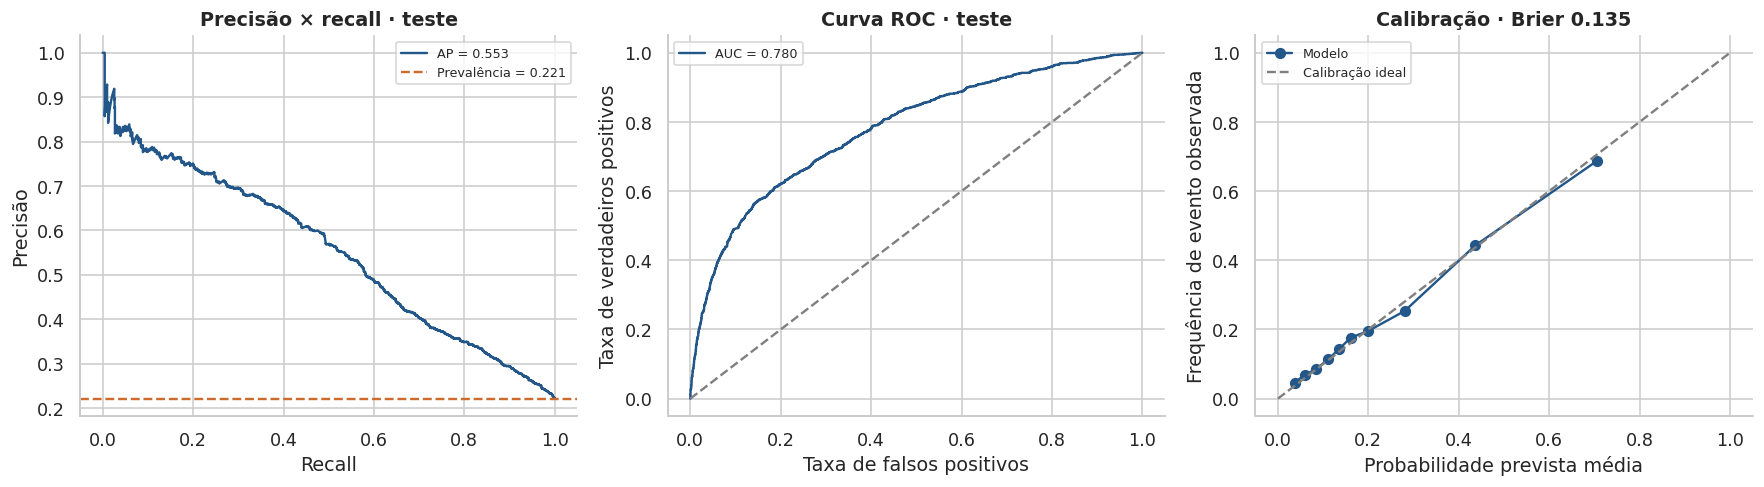

In [18]:
fig, eixos=plt.subplots(1,3,figsize=(15.5,4.4))
pr,rc,_=precision_recall_curve(y_teste,prob_teste)
fpr,tpr,_=roc_curve(y_teste,prob_teste)
eixos[0].plot(rc,pr,color="#235789",label=f"AP = {metricas_teste['average_precision']:.3f}")
eixos[0].axhline(y_teste.mean(),ls="--",color="#cc6b2c",label=f"Prevalência = {y_teste.mean():.3f}")
eixos[0].set(title="Precisão × recall · teste",xlabel="Recall",ylabel="Precisão")
eixos[1].plot(fpr,tpr,color="#235789",label=f"AUC = {metricas_teste['roc_auc']:.3f}")
eixos[1].plot([0,1],[0,1],"--",color="grey")
eixos[1].set(title="Curva ROC · teste",xlabel="Taxa de falsos positivos",ylabel="Taxa de verdadeiros positivos")
fracao_positivos, media_prevista=calibration_curve(y_teste,prob_teste,n_bins=10,strategy="quantile")
eixos[2].plot(media_prevista,fracao_positivos,marker="o",color="#235789",label="Modelo")
eixos[2].plot([0,1],[0,1],"--",color="grey",label="Calibração ideal")
eixos[2].set(title=f"Calibração · Brier {metricas_teste['brier']:.3f}",xlabel="Probabilidade prevista média",ylabel="Frequência de evento observada")
for a in eixos:a.legend(fontsize=8)
plt.tight_layout();plt.show()

In [19]:
# Incerteza no teste por bootstrap estratificado por classe, preservando as proporções.
def intervalo_bootstrap(y_true, scores, n_rep=350, seed=SEED):
    rng=np.random.default_rng(seed)
    y_a=np.asarray(y_true,dtype=int)
    s_a=np.asarray(scores,dtype=float)
    i0=np.flatnonzero(y_a==0); i1=np.flatnonzero(y_a==1)
    funcs={
        "Average Precision":lambda yy,pp:average_precision_score(yy,pp),
        "ROC-AUC":lambda yy,pp:roc_auc_score(yy,pp),
        "Precision@10%":lambda yy,pp:metricas_top_frac(yy,pp)["precision_at_10"],
        "Recall@10%":lambda yy,pp:metricas_top_frac(yy,pp)["recall_at_10"],
        "Lift@10%":lambda yy,pp:metricas_top_frac(yy,pp)["lift_at_10"],
    }
    arr={nome:[] for nome in funcs}
    for _ in range(n_rep):
        idx=np.concatenate([rng.choice(i0,len(i0),replace=True),rng.choice(i1,len(i1),replace=True)])
        for nome,fn in funcs.items():arr[nome].append(fn(y_a[idx],s_a[idx]))
    return pd.DataFrame([{"Métrica":nome,"IC 95% inferior":np.quantile(v,.025),
                          "IC 95% superior":np.quantile(v,.975)} for nome,v in arr.items()])
intervalos=intervalo_bootstrap(y_teste,prob_teste,n_rep=(70 if RAPIDO else 350))
display(intervalos.round(4))
print("Os intervalos refletem variabilidade amostral, não validação temporal ou externa.")

,Métrica,IC 95% inferior,IC 95% superior
0,Average Precision,0.5293,0.5808
1,ROC-AUC,0.7665,0.7948
2,Precision@10%,0.6500,0.7221
3,Recall@10%,0.2939,0.3265
4,Lift@10%,2.9390,3.2651


Os intervalos refletem variabilidade amostral, não validação temporal ou externa.


### Foco operacional: equipe que só pode revisar 10% da carteira

Se todos fossem selecionados aleatoriamente, a taxa esperada de eventos nos casos analisados seria próxima à prevalência da carteira. Ordenando pelo score, calculamos quantos eventos reais se concentram na faixa priorizada. **Lift** é uma medida de concentração relativa, não dinheiro economizado nem causalidade de uma intervenção.

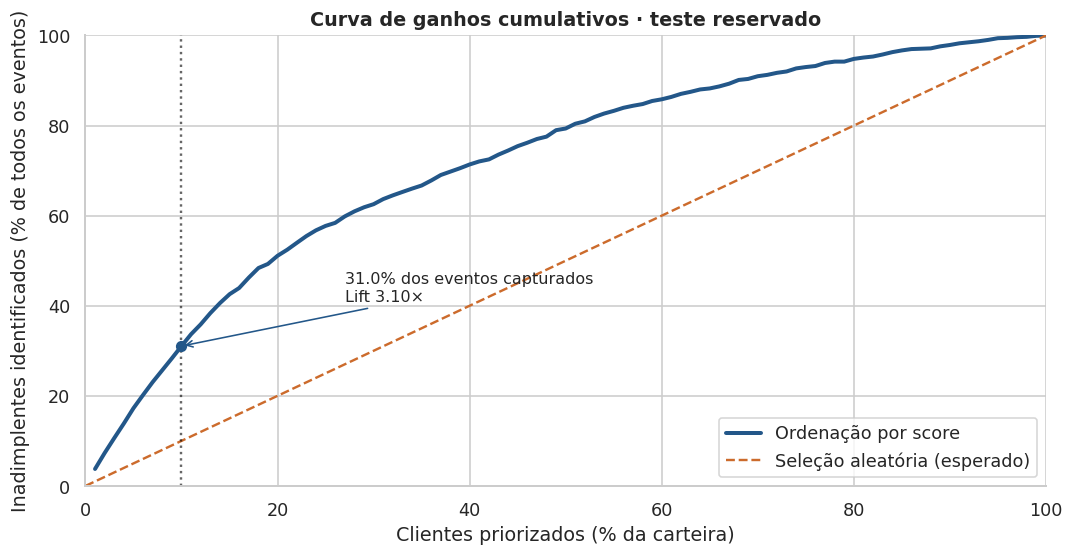

Em 600 casos priorizados, 412 apresentaram inadimplência observada.


In [20]:
ordem_idx=np.argsort(-prob_teste,kind="stable")
y_ordenado=np.asarray(y_teste)[ordem_idx]
limites=np.unique(np.maximum(1,np.ceil(np.linspace(.01,1,100)*len(y_ordenado)).astype(int)))
x_pop=limites/len(y_ordenado)
y_ganhos=np.cumsum(y_ordenado)[limites-1]/max(y_ordenado.sum(),1)
fig,ax=plt.subplots(figsize=(9.5,5))
ax.plot(x_pop*100,y_ganhos*100,label="Ordenação por score",color="#235789",lw=2.5)
ax.plot([0,100],[0,100],"--",color="#cc6b2c",label="Seleção aleatória (esperado)")
ax.axvline(10,ls=":",color="black",alpha=.6)
ax.scatter([10],[metricas_teste["recall_at_10"]*100],color="#235789",zorder=4)
ax.annotate(f"{metricas_teste['recall_at_10']:.1%} dos eventos capturados\nLift {metricas_teste['lift_at_10']:.2f}×",
            xy=(10,metricas_teste["recall_at_10"]*100),xytext=(27,metricas_teste["recall_at_10"]*100+10),
            arrowprops={"arrowstyle":"->","color":"#235789"},fontsize=10)
ax.set(xlim=(0,100),ylim=(0,100),title="Curva de ganhos cumulativos · teste reservado",
       xlabel="Clientes priorizados (% da carteira)",ylabel="Inadimplentes identificados (% de todos os eventos)")
ax.legend(loc="lower right");plt.tight_layout();plt.show()
print(f"Em {metricas_teste['selecionados']:,} casos priorizados, "
      f"{metricas_teste['eventos_selecionados']:,} apresentaram inadimplência observada.")

## 09 · Interpretação, erros e responsabilidade

Importância de atributos mede **contribuição para predição**, não efeito causal. A importância por permutação será obtida em uma **validação interna do treino**, preservando o teste apenas para a avaliação e o diagnóstico final já realizados. Com variáveis mensais correlacionadas, a importância individual pode ficar diluída.

,Atributo,Queda média na AP,DP entre permutações
1,PAY_0,0.0905,0.0116
19,meses_atraso_positivo,0.0693,0.0032
20,maior_atraso_positivo,0.0454,0.0021
26,relacao_pagamentos_faturas,0.0046,0.0039
25,utilizacao_recente,0.0044,0.0020
7,BILL_AMT1,0.0042,0.0024
27,tendencia_fatura_limite,0.0039,0.0017
23,fatura_volatilidade,0.0036,0.0005
0,LIMIT_BAL,0.0035,0.0014
24,pagamento_medio,0.0034,0.0005


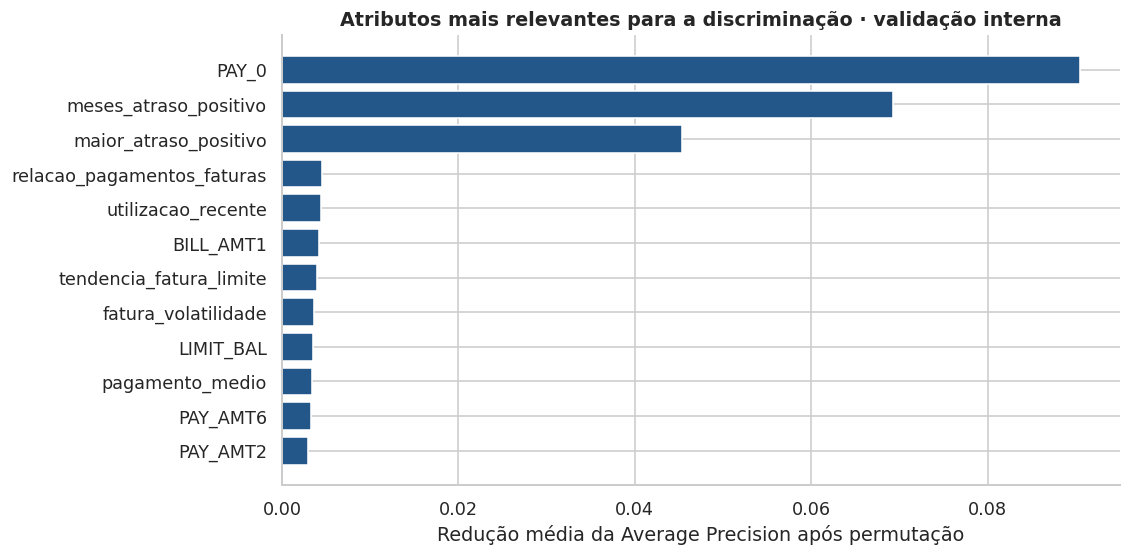

In [21]:
indice_fit,indice_val=train_test_split(np.arange(len(y_treino)),test_size=.20,
    stratify=y_treino,random_state=SEED+20)
interpretavel=clone(pipeline_vencedor)
interpretavel.fit(X_treino.iloc[indice_fit][cols_modelo],y_treino.iloc[indice_fit])
permutacoes=permutation_importance(interpretavel,X_treino.iloc[indice_val][cols_modelo],
    y_treino.iloc[indice_val],scoring="average_precision",n_repeats=(2 if RAPIDO else 3),
    random_state=SEED,n_jobs=1)
ranking_importancia=pd.DataFrame({"Atributo":cols_modelo,
    "Queda média na AP":permutacoes.importances_mean,
    "DP entre permutações":permutacoes.importances_std}).sort_values("Queda média na AP",ascending=False)
display(ranking_importancia.head(12).round(4))
fig,ax=plt.subplots(figsize=(10,5))
top=ranking_importancia.head(12).sort_values("Queda média na AP")
ax.barh(top["Atributo"],top["Queda média na AP"],color="#235789")
ax.set(title="Atributos mais relevantes para a discriminação · validação interna",xlabel="Redução média da Average Precision após permutação")
plt.tight_layout();plt.show()

In [22]:
# Auditoria diagnóstica descritiva em grupos; o modelo não usa esses campos.
# Não constitui análise formal de justiça (fairness), nem recomenda critério de decisão por grupo.
segmentos=pd.DataFrame(index=X_teste_raw.index)
segmentos["sexo_codigo"]="Sexo código "+X_teste_raw.SEX.astype("Int64").astype(str)
segmentos["faixa_etaria"]=np.where(X_teste_raw.AGE<40,"< 40 anos","≥ 40 anos")
segmentos["real"]=y_teste
segmentos["score"]=prob_teste
segmentos["decisao"]=pred_teste
linhas=[]
for atributo in ["sexo_codigo","faixa_etaria"]:
    for valor,g in segmentos.groupby(atributo,dropna=False):
        if len(g)<30:continue
        yy=g.real.to_numpy();pp=g.decisao.to_numpy()
        tn,fp,fn,tp=confusion_matrix(yy,pp,labels=[0,1]).ravel()
        linhas.append({"Grupo":atributo,"Categoria":str(valor),"n":len(g),
                      "Eventos":int(yy.sum()),"Prevalência":yy.mean(),
                      "Recall (TPR)":tp/(tp+fn) if tp+fn else np.nan,
                      "FPR":fp/(fp+tn) if fp+tn else np.nan,
                      "Precisão":tp/(tp+fp) if tp+fp else np.nan})
auditoria_subgrupos=pd.DataFrame(linhas)
display(auditoria_subgrupos.round(3))
print("Diferenças podem refletir composição e tamanho de grupos; não comprovam discriminação/ausência dela.")

,Grupo,Categoria,n,Eventos,Prevalência,Recall (TPR),FPR,Precisão
0,sexo_codigo,Sexo código 1,2402,561,0.234,0.567,0.161,0.518
1,sexo_codigo,Sexo código 2,3598,766,0.213,0.564,0.132,0.536
2,faixa_etaria,< 40 anos,4110,880,0.214,0.569,0.142,0.522
3,faixa_etaria,≥ 40 anos,1890,447,0.237,0.557,0.147,0.540


Diferenças podem refletir composição e tamanho de grupos; não comprovam discriminação/ausência dela.


## 10 · Síntese e entregáveis reprodutíveis

A conclusão de um projeto de risco precisa conectar **discriminação** (AP/AUC), **probabilidades** (calibração/Brier) e **utilidade do ranking** (top 10%), além de explicitar limites. Abaixo, um sumário gerado **a partir dos resultados efetivamente executados**, sem números escritos antecipadamente.

In [23]:
assert np.isfinite(prob_teste).all() and ((prob_teste>=0)&(prob_teste<=1)).all()
assert metricas_teste["selecionados"] == int(np.ceil(.1*len(y_teste)))
assert metricas_teste["eventos_selecionados"] <= metricas_teste["n_eventos"]
assert not set(cols_modelo).intersection(["ID","inadimplente","SEX","EDUCATION","MARRIAGE","AGE"])

relatorio = f"""### Resultado executivo — teste separado

- **População:** {len(dados):,} clientes históricos; {len(y_treino):,} no treino/CV e {len(y_teste):,} no teste estratificado.
- **Modelo:** {nome_vencedor}, usando **{conjunto_escolhido}** ({len(cols_modelo)} atributos financeiros).
- **Discriminação no teste:** AP **{metricas_teste['average_precision']:.3f}** contra prevalência **{metricas_teste['prevalencia_teste']:.3f}**; ROC-AUC **{metricas_teste['roc_auc']:.3f}**.
- **Limiar escolhido por OOF ({limiar_escolhido:.2f}):** precisão **{metricas_teste['precision']:.1%}**, recall **{metricas_teste['recall']:.1%}**, F1 **{metricas_teste['f1']:.3f}**.
- **Operação com capacidade de 10%:** {metricas_teste['eventos_selecionados']:,} eventos entre {metricas_teste['selecionados']:,} clientes; precision@10% **{metricas_teste['precision_at_10']:.1%}**, recall@10% **{metricas_teste['recall_at_10']:.1%}**, lift **{metricas_teste['lift_at_10']:.2f}×**.
- **Qualidade das probabilidades:** Brier score **{metricas_teste['brier']:.4f}**. A curva de calibração deve ser avaliada visualmente antes de interpretar scores como probabilidades individuais confiáveis.

**Conclusão:** o ganho de concentração de eventos no topo do ranking descreve utilidade potencial para *priorização humana*, não retorno financeiro, redução causal de perdas ou autorização automática para negar crédito.

**Limitações materiais:** dados de Taiwan/2005, uma única organização, avaliação aleatória (não temporal), falta de validação externa e de custos de FP/FN, possíveis vieses de coleta/categorização e ausência de auditoria de justiça e conformidade regulatória de implantação.
"""
display(Markdown(relatorio))

### Resultado executivo — teste separado

- **População:** 30,000 clientes históricos; 24,000 no treino/CV e 6,000 no teste estratificado.
- **Modelo:** Gradient Boosting, usando **Financeiros + engenharia** (28 atributos financeiros).
- **Discriminação no teste:** AP **0.553** contra prevalência **0.221**; ROC-AUC **0.780**.
- **Limiar escolhido por OOF (0.29):** precisão **52.8%**, recall **56.5%**, F1 **0.546**.
- **Operação com capacidade de 10%:** 412 eventos entre 600 clientes; precision@10% **68.7%**, recall@10% **31.0%**, lift **3.10×**.
- **Qualidade das probabilidades:** Brier score **0.1350**. A curva de calibração deve ser avaliada visualmente antes de interpretar scores como probabilidades individuais confiáveis.

**Conclusão:** o ganho de concentração de eventos no topo do ranking descreve utilidade potencial para *priorização humana*, não retorno financeiro, redução causal de perdas ou autorização automática para negar crédito.

**Limitações materiais:** dados de Taiwan/2005, uma única organização, avaliação aleatória (não temporal), falta de validação externa e de custos de FP/FN, possíveis vieses de coleta/categorização e ausência de auditoria de justiça e conformidade regulatória de implantação.


In [24]:
# Exporta artefatos pequenos e legíveis, preservando metadados de escopo e versão.
# Joblib contém código serializado: carregar SOMENTE se você confiar na procedência.
PASTA_ARTEFATOS.mkdir(parents=True,exist_ok=True)
resultados_ablacao.to_csv(PASTA_ARTEFATOS/"ablacao.csv",index=False)
resultados_modelos.to_csv(PASTA_ARTEFATOS/"modelos_cv.csv",index=False)
resultado_balanceamento.to_csv(PASTA_ARTEFATOS/"balanceamento_cv.csv",index=False)
ranking_importancia.to_csv(PASTA_ARTEFATOS/"importancia_permutacao.csv",index=False)
auditoria_subgrupos.to_csv(PASTA_ARTEFATOS/"auditoria_subgrupos.csv",index=False)
intervalos.to_csv(PASTA_ARTEFATOS/"intervalos_bootstrap.csv",index=False)
with open(PASTA_ARTEFATOS/"metricas_teste.json","w",encoding="utf-8") as f:
    json.dump(metricas_teste,f,ensure_ascii=False,indent=2)
with open(PASTA_ARTEFATOS/"relatorio_executivo.md","w",encoding="utf-8") as f:
    f.write(relatorio)
manifesto={"fonte":origem_dados,"doi":"https://doi.org/10.24432/C55S3H",
           "algoritmo":nome_vencedor,"representacao":conjunto_escolhido,
           "features":cols_modelo,"limiar":limiar_escolhido,
           "particao_teste":.20,"seed":SEED,"folds_cv":CV.n_splits,
           "treino_n":len(y_treino),"teste_n":len(y_teste),"modo_rapido":RAPIDO,
           "python":platform.python_version(),"sklearn":sklearn.__version__,
           "aviso":"Pesquisa histórica: não utilizar para decisão automática real de crédito."}
with open(PASTA_ARTEFATOS/"manifesto.json","w",encoding="utf-8") as f:
    json.dump(manifesto,f,ensure_ascii=False,indent=2)
dump(modelo_final,PASTA_ARTEFATOS/"modelo_experimental.joblib")
print("Artefatos gerados em:",PASTA_ARTEFATOS.resolve())
print("Inclui modelo EXPERIMENTAL: não disponibilizar como serviço de decisões reais.")

Artefatos gerados em: /content/artefatos_credit_risk
Inclui modelo EXPERIMENTAL: não disponibilizar como serviço de decisões reais.


---
## Notas técnicas, fontes e uso responsável

- **Fonte primária:** Yeh, I.-C. (2009), *Default of Credit Card Clients*, UCI Machine Learning Repository. DOI [10.24432/C55S3H](https://doi.org/10.24432/C55S3H); base sob licença **CC BY 4.0**.
- **Artigo associado:** Yeh & Lien (2009), *The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients*, *Expert Systems with Applications*, 36(2), 2473–2480.
- **Vazamento e validação:** [scikit-learn — Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html); [imbalanced-learn — Common pitfalls](https://imbalanced-learn.org/stable/common_pitfalls.html).
- **Métricas:** [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html); [Curvas precision-recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html); [Calibração](https://scikit-learn.org/stable/modules/calibration.html).

**Ética e validade:** este estudo não é ferramenta de decisão creditícia. Atributos demográficos foram investigados apenas na ablação, não usados no modelo final. Remover variáveis demográficas não elimina necessariamente *proxies* e disparidades. Qualquer implantação exige dados atuais e legalmente apropriados, estudo de impacto, validação temporal e externa, supervisão humana, monitoramento e documentação das regras e dos custos de decisão.

**Reprodução:** execute todas as células em ordem. Se o acesso à UCI falhar, baixe o `.xls` oficial, instale `xlrd` e aponte `CREDIT_DATA_LOCAL` para o arquivo. Nunca confunda testes sintéticos de código com evidência empírica sobre a população UCI.